In [ ]:
import pandas as pd
import numpy as np

In [ ]:
 pip install openpyxl

In [ ]:
df=pd.read_excel("/content/drive/MyDrive/Online Retail.xlsx")

In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(541909, 8)


In [ ]:
print(df.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
df.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
5268


In [ ]:
print("Missing CustomerID:")
print(df["CustomerID"].isnull().sum())

Missing CustomerID:
135080


In [ ]:
print("Missing Description:")
print(df["Description"].isnull().sum())

Missing Description:
1454


In [ ]:
print("Invalid quantity:")
print((df["Quantity"]<=0).sum())

Invalid quantity:
10624


In [ ]:
print("Invalid Unitprice:")
print((df["UnitPrice"]<=0).sum())

Invalid Unitprice:
2517


In [ ]:
print("Cancelled Records:")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())

Cancelled Records:
9288


In [ ]:
# Positive Sales Rows - Original Dataset

positive_sales_raw = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

print("Original Positive Sales Rows:")
print(len(positive_sales_raw))

Original Positive Sales Rows:
530104


In [ ]:
data_quality = pd.DataFrame({
    "Check": [
        "Raw Data Rows",
        "Duplicate Rows",
        "Missing Description",
        "Missing CustomerID",
        "Invalid Quantity",
        "Invalid UnitPrice",
        "Cancellation Records"
    ],
    "Value": [
        len(df),
        df.duplicated().sum(),
        df["Description"].isnull().sum(),
        df["CustomerID"].isnull().sum(),
        (df["Quantity"] <= 0).sum(),
        (df["UnitPrice"] <= 0).sum(),
        df["InvoiceNo"].astype(str).str.startswith("C").sum()
    ]
})

print(data_quality)

                  Check   Value
0         Raw Data Rows  541909
1        Duplicate Rows    5268
2   Missing Description    1454
3    Missing CustomerID  135080
4      Invalid Quantity   10624
5     Invalid UnitPrice    2517
6  Cancellation Records    9288


In [ ]:
df_clean=df.drop_duplicates().copy()

print("Original Rows:",len(df))
print("Rows After Removing Duplicates:",len(df_clean))
print("Duplicate Rows Remaining:",df_clean.duplicated().sum())

Original Rows: 541909
Rows After Removing Duplicates: 536641
Duplicate Rows Remaining: 0


In [ ]:
print("Missing Values After Removing Duplicates:")
print(df_clean.isnull().sum())

Missing Values After Removing Duplicates:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [ ]:
# Cleaned Data - Missing CustomerID Check

print("Missing CustomerID:")
print(df_clean["CustomerID"].isnull().sum())

Missing CustomerID:
135037


In [ ]:
# Cleaned Data - Missing Description Check

print("Missing Description:")
print(df_clean["Description"].isnull().sum())

Missing Description:
1454


In [ ]:
# Cleaned Data - Invalid Quantity Check

print("Invalid Quantity:")
print((df_clean["Quantity"] <= 0).sum())

Invalid Quantity:
10587


In [ ]:
# Cleaned Data - Invalid UnitPrice Check

print("Invalid UnitPrice:")
print((df_clean["UnitPrice"] <= 0).sum())

Invalid UnitPrice:
2512


In [ ]:
# Cleaned Data - Cancellation Records

print("Cancellation Records:")
print(df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())

Cancellation Records:
9251


In [ ]:
# Positive Sales Rows Check

positive_sales = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C")) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

print("Positive Sales Rows:")
print(len(positive_sales))

Positive Sales Rows:
524878


In [ ]:
# Excluded Rows Check

print("Excluded Rows:")
print(len(df_clean) - len(positive_sales))

Excluded Rows:
11763


In [ ]:
# Check Excluded Rows by Reason

print("Cancellation Invoices:")
print(df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Zero or Negative Quantity:")
print((df_clean["Quantity"] <= 0).sum())

print("Zero or Negative UnitPrice:")
print((df_clean["UnitPrice"] <= 0).sum())

Cancellation Invoices:
9251
Zero or Negative Quantity:
10587
Zero or Negative UnitPrice:
2512


In [ ]:
# Excluded Rows - Check Each Rule

cancel_rows = df_clean["InvoiceNo"].astype(str).str.startswith("C")
invalid_quantity = df_clean["Quantity"] <= 0
invalid_price = df_clean["UnitPrice"] <= 0

print("Cancellation Rows:", cancel_rows.sum())
print("Invalid Quantity Rows:", invalid_quantity.sum())
print("Invalid UnitPrice Rows:", invalid_price.sum())

print("Rows Excluded by Combined Rules:")
print((cancel_rows | invalid_quantity | invalid_price).sum())

Cancellation Rows: 9251
Invalid Quantity Rows: 10587
Invalid UnitPrice Rows: 2512
Rows Excluded by Combined Rules:
11763


In [ ]:
# Cleaned Data - Final Verification

print("Original Rows:", len(df))
print("Cleaned Rows:", len(df_clean))
print("Duplicate Rows Remaining:", df_clean.duplicated().sum())
print("Missing Values:")
print(df_clean.isnull().sum())

Original Rows: 541909
Cleaned Rows: 536641
Duplicate Rows Remaining: 0
Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [ ]:
# Cleaned Data - Total Revenue

print("Total Revenue:")
print((df_clean["Quantity"] * df_clean["UnitPrice"]).sum())

Total Revenue:
9726006.953999998


In [ ]:
# Cleaned Data - Valid Revenue

df_clean["Valid Revenue"] = np.where(
    (df_clean["InvoiceNo"].astype(str).str.startswith("C") == False) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0),
    df_clean["Quantity"] * df_clean["UnitPrice"],
    0
)

print("Total Valid Revenue:")
print(df_clean["Valid Revenue"].sum())

Total Valid Revenue:
10642110.804000001


In [ ]:
# Cleaned Data - Total Quantity Sold

print("Total Quantity Sold:")
print(df_clean["Quantity"].sum())

Total Quantity Sold:
5162502


In [ ]:
# Cleaned Data - Total Orders

print("Total Orders:")
print(df_clean["InvoiceNo"].nunique())

Total Orders:
25900


In [ ]:
# Cleaned Data - Total Customers

print("Total Customers:")
print(df_clean["CustomerID"].nunique())

Total Customers:
4372


In [ ]:
# Cleaned Data - Total Products

print("Total Products:")
print(df_clean["StockCode"].nunique())

Total Products:
4070


In [ ]:
# Cleaned Data - Average Order Value

total_revenue = df_clean["Valid Revenue"].sum()
total_orders = df_clean["InvoiceNo"].nunique()

print("Average Order Value:")
print(total_revenue / total_orders)

Average Order Value:
410.8923090347491


In [ ]:
# Cleaned Data - Revenue per Customer

total_revenue = df_clean["Valid Revenue"].sum()
total_customers = df_clean["CustomerID"].nunique()

print("Revenue per Customer:")
print(total_revenue / total_customers)

Revenue per Customer:
2434.1516020128092


In [ ]:
# Business Calculations - Valid Positive Sales

sales = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

# Total Transactions
print("Total Transactions:", len(sales))

# Total Revenue
total_revenue = sales["Revenue"].sum()
print("Total Revenue:", round(total_revenue, 2))

# Total Quantity
total_quantity = sales["Quantity"].sum()
print("Total Quantity Sold:", total_quantity)

# Total Orders
total_orders = sales["InvoiceNo"].nunique()
print("Total Orders:", total_orders)

# Total Customers
total_customers = sales["CustomerID"].nunique()
print("Total Customers:", total_customers)

# Total Products
total_products = sales["StockCode"].nunique()
print("Total Products:", total_products)

# Average Order Value
average_order_value = total_revenue / total_orders
print("Average Order Value:", round(average_order_value, 2))

# Revenue per Customer
revenue_per_customer = (
    total_revenue / sales["CustomerID"].nunique()
)
print("Revenue per Customer:", round(revenue_per_customer, 2))

Total Transactions: 524878
Total Revenue: 10642110.8
Total Quantity Sold: 5572420
Total Orders: 19960
Total Customers: 4338
Total Products: 3922
Average Order Value: 533.17
Revenue per Customer: 2453.23


In [ ]:

# Calculation

total_revenue = df_clean["Valid Revenue"].sum()

sales = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C")) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

total_quantity = sales["Quantity"].sum()
total_orders = sales["InvoiceNo"].nunique()
total_customers = sales["CustomerID"].nunique()
total_products = sales["StockCode"].nunique()

average_order_value = total_revenue / total_orders
revenue_per_customer = total_revenue / total_customers

calculation = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Quantity Sold",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Average Order Value",
        "Revenue per Customer"
    ],
    "Value": [
        round(total_revenue, 2),
        int(total_quantity),
        int(total_orders),
        int(total_customers),
        int(total_products),
        round(average_order_value, 2),
        round(revenue_per_customer, 2)
    ]
})

print(calculation.to_string(index=False))

              Metric       Value
       Total Revenue 10642110.80
 Total Quantity Sold  5572420.00
        Total Orders    19960.00
     Total Customers     4338.00
      Total Products     3922.00
 Average Order Value      533.17
Revenue per Customer     2453.23


In [ ]:

# Exploratory Data Analysis (EDA)

print("1. Revenue Statistics")
print(df_clean["Valid Revenue"].describe())

print("\n2. Quantity Statistics")
print(df_clean["Quantity"].describe())

print("\n3. Top 10 Products by Quantity Sold")
print(
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\n4. Top 10 Countries by Transaction Count")
print(
    df_clean.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

1. Revenue Statistics
count    536641.000000
mean         19.830969
std         268.715743
min           0.000000
25%           3.750000
50%           9.870000
75%          17.400000
max      168469.600000
Name: Valid Revenue, dtype: float64

2. Quantity Statistics
count    536641.000000
mean          9.620029
std         219.130156
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

3. Top 10 Products by Quantity Sold
Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47260
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35298
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26299
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64



In [ ]:
# Cleaned Data - Top 10 Products by Revenue

top_products = df_clean.groupby("Description")["Valid Revenue"].sum()

print("Top 10 Products by Revenue:")
print(top_products.sort_values(ascending=False).head(10))

Top 10 Products by Revenue:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Valid Revenue, dtype: float64


In [ ]:
# Cleaned Data - Top 10 Products by Quantity Sold

top_products_quantity = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
print(top_products_quantity)

Top 10 Products by Quantity Sold:
Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47260
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35298
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26299
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64


In [ ]:
# Cleaned Data - Country-wise Revenue

country_revenue = df_clean.groupby("Country")["Valid Revenue"].sum()

print("Country-wise Revenue:")
print(country_revenue.sort_values(ascending=False))

Country-wise Revenue:
Country
United Kingdom          9001744.094
Netherlands              285446.340
EIRE                     283140.520
Germany                  228678.400
France                   209625.370
Australia                138453.810
Spain                     61558.560
Switzerland               57067.600
Belgium                   41196.340
Sweden                    38367.830
Japan                     37416.370
Norway                    36165.440
Portugal                  33683.050
Finland                   22546.080
Singapore                 21279.290
Channel Islands           20440.540
Denmark                   18955.340
Italy                     17483.240
Hong Kong                 15483.000
Cyprus                    13502.850
Austria                   10198.680
Israel                     8129.410
Poland                     7334.650
Greece                     4760.520
Unspecified                4740.940
Iceland                    4310.000
Canada                     3666.38

In [ ]:

# Business Analysis - Country-wise Sales

country_analysis = df_clean.groupby("Country").agg(
    Total_Revenue=("Valid Revenue", "sum"),
    Total_Orders=("InvoiceNo", "nunique")
).sort_values("Total_Revenue", ascending=False)

print(country_analysis.head(10).round(2))

                Total_Revenue  Total_Orders
Country                                    
United Kingdom     9001744.09         23494
Netherlands         285446.34           101
EIRE                283140.52           360
Germany             228678.40           603
France              209625.37           461
Australia           138453.81            69
Spain                61558.56           105
Switzerland          57067.60            74
Belgium              41196.34           119
Sweden               38367.83            46


In [ ]:
# Cleaned Data - Country-wise Sales Analysis

country_summary = df_clean.groupby("Country").agg(
    Total_Revenue=("Valid Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("InvoiceNo", "nunique")
)

print("Top 10 Countries by Revenue:")
print(country_summary.sort_values(
    by="Total_Revenue", ascending=False
).head(10))

Top 10 Countries by Revenue:
                Total_Revenue  Total_Quantity  Total_Orders
Country                                                    
United Kingdom    9001744.094         4250328         23494
Netherlands        285446.340          200128           101
EIRE               283140.520          142495           360
Germany            228678.400          117341           603
France             209625.370          110438           461
Australia          138453.810           83643            69
Spain               61558.560           26817           105
Switzerland         57067.600           30313            74
Belgium             41196.340           23152           119
Sweden              38367.830           35632            46


In [ ]:
# Cleaned Data - Country-wise Order Count

country_orders = df_clean.groupby("Country")["InvoiceNo"].nunique()

print("Country-wise Order Count:")
print(country_orders.sort_values(ascending=False))

Country-wise Order Count:
Country
United Kingdom          23494
Germany                   603
France                    461
EIRE                      360
Belgium                   119
Spain                     105
Netherlands               101
Switzerland                74
Portugal                   71
Australia                  69
Italy                      55
Finland                    48
Sweden                     46
Norway                     40
Channel Islands            33
Japan                      28
Poland                     24
Denmark                    21
Cyprus                     20
Austria                    19
Hong Kong                  15
Unspecified                13
Malta                      10
Singapore                  10
Israel                      9
Iceland                     7
USA                         7
Greece                      6
Canada                      6
Czech Republic              5
European Community          5
Bahrain                     4
Lithua

In [ ]:
# Cleaned Data - Quantity by Country

country_quantity = df_clean.groupby("Country")["Quantity"].sum()

print("Quantity Sold by Country:")
print(country_quantity.sort_values(ascending=False))

Quantity Sold by Country:
Country
United Kingdom          4250328
Netherlands              200128
EIRE                     142495
Germany                  117341
France                   110438
Australia                 83643
Sweden                    35632
Switzerland               30313
Spain                     26817
Japan                     25218
Belgium                   23152
Norway                    19247
Portugal                  16153
Finland                   10666
Channel Islands            9473
Denmark                    8188
Italy                      7999
Cyprus                     6296
Singapore                  5234
Austria                    4827
Hong Kong                  4709
Israel                     4350
Poland                     3653
Unspecified                3295
Canada                     2763
Iceland                    2458
Greece                     1556
USA                        1034
United Arab Emirates        982
Malta                       944
Lithua

In [ ]:
# Cleaned Data - Top 10 Customers by Country

country_customer_revenue = (
    df_clean.groupby(["Country", "CustomerID"])["Valid Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Country-Customer Combinations by Revenue:")
print(country_customer_revenue.head(10))

Top 10 Country-Customer Combinations by Revenue:
Country         CustomerID
Netherlands     14646.0       280206.02
United Kingdom  18102.0       259657.30
                17450.0       194390.79
                16446.0       168472.50
EIRE            14911.0       143711.17
Australia       12415.0       124914.53
EIRE            14156.0       117210.08
United Kingdom  17511.0        91062.38
                16029.0        80850.84
                12346.0        77183.60
Name: Valid Revenue, dtype: float64


In [ ]:
# Cleaned Data - Daily Revenue

df_clean["Date"] = df_clean["InvoiceDate"].dt.date

daily_revenue = df_clean.groupby("Date")["Valid Revenue"].sum()

print("Daily Revenue:")
print(daily_revenue)

Daily Revenue:
Date
2010-12-01     58776.79
2010-12-02     47629.42
2010-12-03     46898.63
2010-12-05     31364.63
2010-12-06     54624.15
                ...    
2011-12-05     88620.84
2011-12-06     56558.83
2011-12-07     75315.55
2011-12-08     82371.55
2011-12-09    200900.98
Name: Valid Revenue, Length: 305, dtype: float64


In [ ]:
# Cleaned Data - Monthly Revenue

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")

monthly_revenue = df_clean.groupby("Month")["Valid Revenue"].sum()

print("Monthly Revenue:")
print(monthly_revenue)

Monthly Revenue:
Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Valid Revenue, dtype: float64


In [ ]:
# Cleaned Data - Monthly Revenue Summary

monthly_summary = df_clean.groupby("Month").agg(
    Total_Revenue=("Valid Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("InvoiceNo", "nunique")
)

print("Monthly Revenue Summary:")
print(monthly_summary)

Monthly Revenue Summary:
         Total_Revenue  Total_Quantity  Total_Orders
Month                                               
2010-12     821452.730          341038          2025
2011-01     689811.610          308281          1476
2011-02     522545.560          277374          1393
2011-03     716215.260          351165          1983
2011-04     536968.491          288237          1744
2011-05     769296.610          379652          2162
2011-06     760547.010          340945          2012
2011-07     718076.121          389051          1927
2011-08     757841.380          405450          1737
2011-09    1056435.192          548669          2327
2011-10    1151263.730          569749          2637
2011-11    1503866.780          737182          3462
2011-12     637790.330          225709          1015


In [ ]:
# Cleaned Data - Revenue by Day of Week

df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()

weekday_revenue = df_clean.groupby("DayOfWeek")["Valid Revenue"].sum()

print("Revenue by Day of Week:")
print(weekday_revenue.sort_values(ascending=False))

Revenue by Day of Week:
DayOfWeek
Thursday     2199292.570
Tuesday      2175700.511
Wednesday    1847074.380
Friday       1837470.491
Monday       1775782.071
Sunday        806790.781
Name: Valid Revenue, dtype: float64


In [ ]:
# Cleaned Data - Revenue by Hour

df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

hourly_revenue = df_clean.groupby("Hour")["Valid Revenue"].sum()

print("Revenue by Hour:")
print(hourly_revenue.sort_values(ascending=False))

Revenue by Hour:
Hour
10    1444814.771
12    1439324.660
15    1350333.310
13    1261195.200
11    1236573.290
14    1177907.521
9      990054.991
16     752487.960
17     460963.921
8      283750.680
18     144603.610
19      50204.950
7       31059.210
20      18832.480
6           4.250
Name: Valid Revenue, dtype: float64


In [ ]:
# Cleaned Data - Quarterly Revenue

quarterly_revenue = df_clean.groupby(
    df_clean["InvoiceDate"].dt.to_period("Q")
)["Valid Revenue"].sum()

print("Quarterly Revenue:")
print(quarterly_revenue)

Quarterly Revenue:
InvoiceDate
2010Q4     821452.730
2011Q1    1928572.430
2011Q2    2066812.111
2011Q3    2532352.693
2011Q4    3292920.840
Freq: Q-DEC, Name: Valid Revenue, dtype: float64


In [ ]:

# Time Analysis - Revenue by Day of Week

day_revenue = (
    df_clean.groupby("DayOfWeek")["Valid Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Day of Week:")
print(day_revenue.round(2))

Revenue by Day of Week:
DayOfWeek
Thursday     2199292.57
Tuesday      2175700.51
Wednesday    1847074.38
Friday       1837470.49
Monday       1775782.07
Sunday        806790.78
Name: Valid Revenue, dtype: float64


In [ ]:
# Cleaned Data - Top 10 Customers by Revenue

customer_revenue = df_clean.groupby("CustomerID")["Valid Revenue"].sum()

print("Top 10 Customers by Revenue:")
print(customer_revenue.sort_values(ascending=False).head(10))

Top 10 Customers by Revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Valid Revenue, dtype: float64


In [ ]:
# Cleaned Data - Customer Purchase Frequency

customer_orders = df_clean.groupby("CustomerID")["InvoiceNo"].nunique()

print("Top 10 Customers by Number of Orders:")
print(customer_orders.sort_values(ascending=False).head(10))

Top 10 Customers by Number of Orders:
CustomerID
14911.0    248
12748.0    224
17841.0    169
14606.0    128
15311.0    118
13089.0    118
12971.0     89
14527.0     86
13408.0     81
14646.0     77
Name: InvoiceNo, dtype: int64


In [ ]:

# One-Time vs Returning Customers

sales = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].dropna(subset=["CustomerID"])

customer_orders = sales.groupby("CustomerID")[
    "InvoiceNo"
].nunique()

one_time = (customer_orders == 1).sum()
returning = (customer_orders > 1).sum()

print("One-Time Customers:", one_time)
print("Returning Customers:", returning)
print("Total Customers:", len(customer_orders))

One-Time Customers: 1494
Returning Customers: 2845
Total Customers: 4339


In [ ]:
# Cleaned Data - Cancellation vs Regular Invoices

df_clean["OrderType"] = df_clean["InvoiceNo"].astype(str).str.startswith("C")

print("Invoice Type Counts:")
print(df_clean["OrderType"].map({True: "Cancellation", False: "Regular"}).value_counts())

Invoice Type Counts:
OrderType
Regular         527390
Cancellation      9251
Name: count, dtype: int64


In [ ]:
# Cleaned Data - Cancellation Analysis

cancellations = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Total Cancellation Rows:", len(cancellations))
print("Cancellation Quantity:", cancellations["Quantity"].sum())
print(
    "Cancellation Revenue:",
    (cancellations["Quantity"] * cancellations["UnitPrice"]).sum()
)
print(
    "Unique Cancellation Invoices:",
    cancellations["InvoiceNo"].nunique()
)

Total Cancellation Rows: 9251
Cancellation Quantity: -275560
Cancellation Revenue: -893979.7300000001
Unique Cancellation Invoices: 3836


In [ ]:

# Cancellation Analysis

cancelled = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

regular = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancellation Transactions:", len(cancelled))
print("Regular Transactions:", len(regular))

print("Cancellation Quantity:",
      cancelled["Quantity"].sum())

print("Regular Quantity:",
      regular["Quantity"].sum())

Cancellation Transactions: 9251
Regular Transactions: 527390
Cancellation Quantity: -275560
Regular Quantity: 5438062


In [ ]:
# Cleaned Data - Order Value Analysis

order_revenue = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C")) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].groupby("InvoiceNo")["Valid Revenue"].sum()

print("Total Valid Orders:", len(order_revenue))
print("Average Order Value:", order_revenue.mean())
print("Highest Order Value:", order_revenue.max())

Total Valid Orders: 19960
Average Order Value: 533.1718839679359
Highest Order Value: 168469.6


In [ ]:
# Cleaned Data - Revenue Statistics

valid_revenue = df_clean["Valid Revenue"]

print("Total Revenue:", valid_revenue.sum())
print("Average Revenue per Row:", valid_revenue.mean())
print("Highest Row Revenue:", valid_revenue.max())
print("Lowest Row Revenue:", valid_revenue[valid_revenue > 0].min())

Total Revenue: 10642110.804000001
Average Revenue per Row: 19.83096856930425
Highest Row Revenue: 168469.6
Lowest Row Revenue: 0.001


In [ ]:
# Cleaned Data - Order Size Analysis

order_size = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C")) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].groupby("InvoiceNo")["Quantity"].sum()

print("Average Items per Order:", order_size.mean())
print("Largest Order by Quantity:", order_size.max())
print("Smallest Order by Quantity:", order_size.min())

Average Items per Order: 279.17935871743487
Largest Order by Quantity: 80995
Smallest Order by Quantity: 1


In [ ]:
print(df_clean.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Valid Revenue', 'Date', 'Month', 'DayOfWeek', 'Hour', 'OrderType']


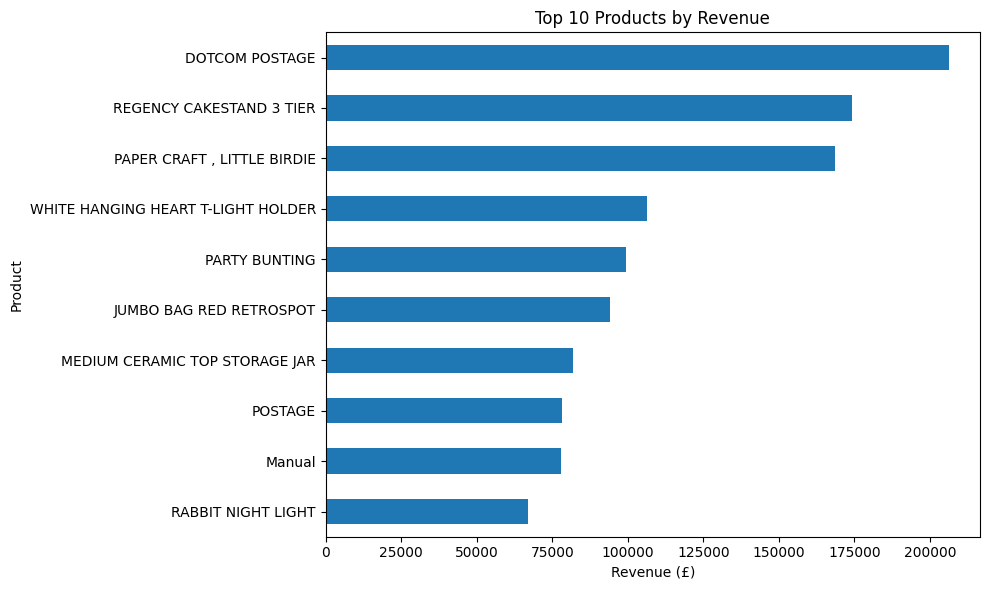

In [ ]:
# Matplotlib - Top 10 Products by Revenue

import matplotlib.pyplot as plt

top_products = (
    df_clean.groupby("Description")["Valid Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

top_products.plot(kind="barh", figsize=(10, 6))

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

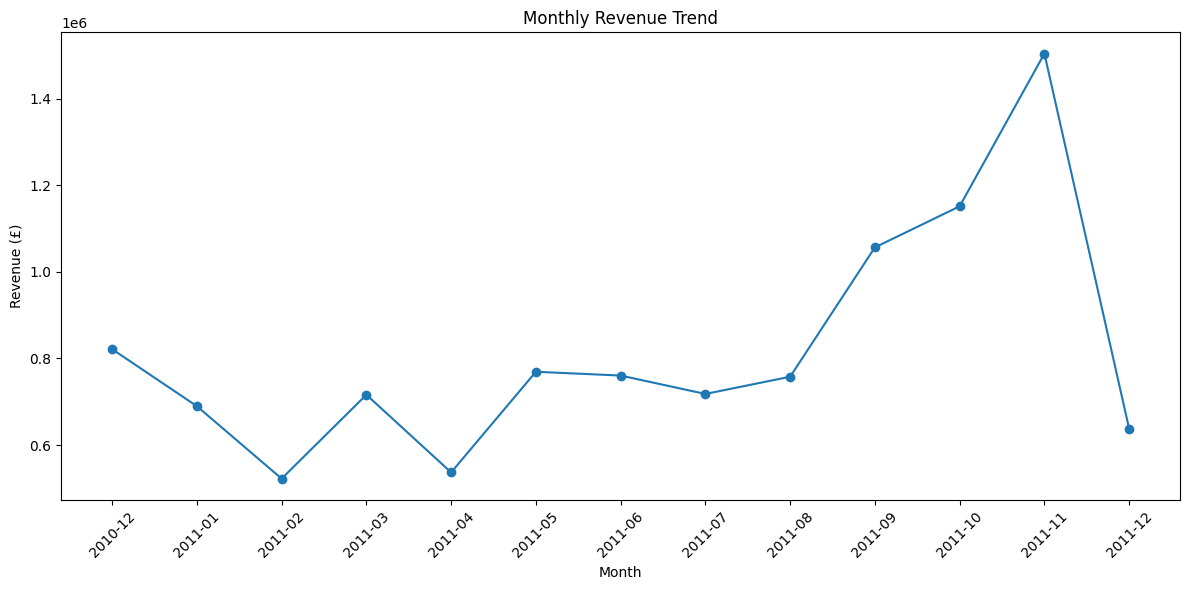

In [ ]:

# Monthly Revenue Trend

import pandas as pd
import matplotlib.pyplot as plt

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

monthly_revenue = df_clean.groupby(
    df_clean["InvoiceDate"].dt.to_period("M")
)["Valid Revenue"].sum()

monthly_revenue.index = monthly_revenue.index.astype(str)

plt.figure(figsize=(12, 6))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

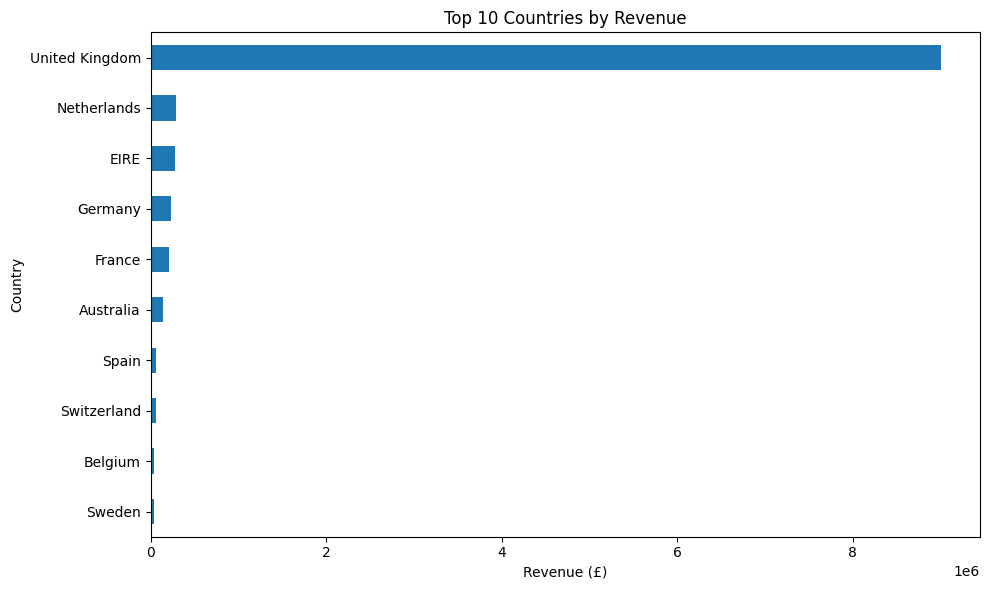

In [ ]:

# Top 10 Countries by Revenue

top_countries = (
    df_clean.groupby("Country")["Valid Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

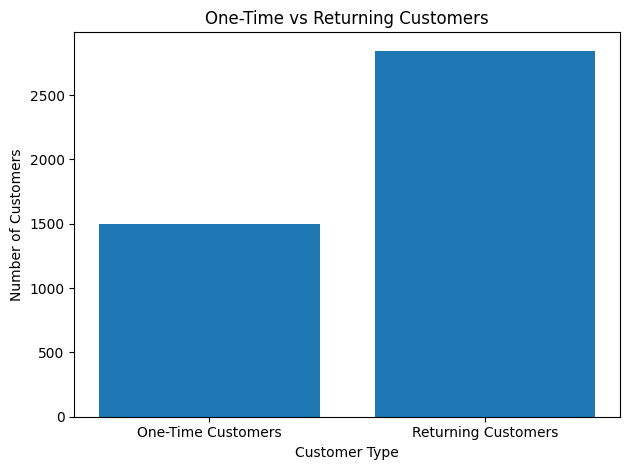

In [ ]:


# One-Time vs Returning Customers Chart

import matplotlib.pyplot as plt

sales = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].dropna(subset=["CustomerID"])

customer_orders = sales.groupby("CustomerID")["InvoiceNo"].nunique()

one_time = (customer_orders == 1).sum()
returning = (customer_orders > 1).sum()

plt.bar(
    ["One-Time Customers", "Returning Customers"],
    [one_time, returning]
)

plt.title("One-Time vs Returning Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Regular Sales Revenue: 10619986.68
Cancellation Impact: -893979.73


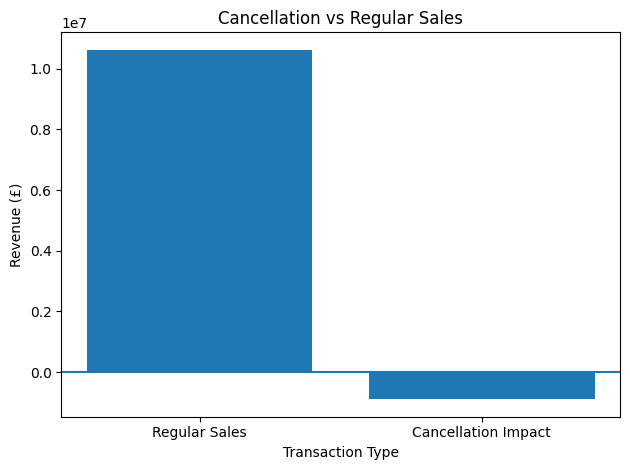

In [ ]:


# Cancellation vs Regular Sales Comparison

import matplotlib.pyplot as plt

cancelled = df_clean["InvoiceNo"].astype(str).str.startswith("C")

regular_sales = (
    df_clean.loc[~cancelled, "Quantity"] *
    df_clean.loc[~cancelled, "UnitPrice"]
).sum()

cancellation_impact = (
    df_clean.loc[cancelled, "Quantity"] *
    df_clean.loc[cancelled, "UnitPrice"]
).sum()

print("Regular Sales Revenue:", round(regular_sales, 2))
print("Cancellation Impact:", round(cancellation_impact, 2))

plt.bar(
    ["Regular Sales", "Cancellation Impact"],
    [regular_sales, cancellation_impact]
)

plt.title("Cancellation vs Regular Sales")
plt.xlabel("Transaction Type")
plt.ylabel("Revenue (£)")
plt.axhline(y=0)
plt.tight_layout()
plt.show()

In [ ]:

# Verify Customer and Product Counts

print("Total Rows:", len(df_clean))

print("Unique Customers:",
      df_clean["CustomerID"].nunique())

print("Unique Product Codes:",
      df_clean["StockCode"].nunique())

print("Unique Product Descriptions:",
      df_clean["Description"].nunique())

Total Rows: 536641
Unique Customers: 4372
Unique Product Codes: 4070
Unique Product Descriptions: 4223


In [ ]:

print("Unique StockCodes:", df_clean["StockCode"].nunique())
print("Unique Descriptions:", df_clean["Description"].nunique())
print("Customers in cleaned data:", df_clean["CustomerID"].nunique())
print("Customers in positive sales:", sales["CustomerID"].nunique())

Unique StockCodes: 4070
Unique Descriptions: 4223
Customers in cleaned data: 4372
Customers in positive sales: 4339


Final Business Insights


Product Analysis: Identify the top-performing products based on revenue and quantity sold to support inventory planning.



Customer Analysis: Compare one-time and returning customers to understand purchasing behaviour and customer retention.



Market Analysis: Compare revenue and order counts across countries to identify the strongest markets.



Time Analysis: Analyse monthly revenue and day-wise sales patterns to understand sales trends.



Cancellation Analysis: Examine cancelled transactions, quantities and their negative revenue impact.



Business Performance: Evaluate total revenue, quantity sold, total orders, average order value and revenue per customer to understand overall business performance.



Visualisation: Use Matplotlib charts to communicate product performance, monthly trends, country-wise revenue and cancellation impact.



Conclusion
The Online Retail dataset provides insights into sales performance, product demand, customer purchasing behaviour, country-wise market contribution, time-based sales trends and cancellations. These findings can help support data-driven business decisions related to inventory planning, customer retention and sales improvement.

In [ ]:
import pandas as pd
import os

output_file = "/content/Online_Retail_Complete_Analysis.xlsx"

sheets = {
    "Raw Data": df,
    "Cleaned Data": df_clean,
    "Data Quality": data_quality,
    "Calculation": calculation,
    "Exploratory Analysis": country_summary,
    "Product Analysis": top_products.rename("Revenue").to_frame(),
    "Product Quantity": top_products_quantity.rename("Quantity").to_frame(),
    "Market Analysis": country_analysis,
    "Country Summary": country_summary,
    "Customer Revenue": customer_revenue.rename("Revenue").to_frame(),
    "Customer Orders": customer_orders.rename("Orders").to_frame(),
    "Time Analysis": monthly_summary,
    "Daily Revenue": daily_revenue.rename("Revenue").to_frame(),
    "Hourly Revenue": hourly_revenue.rename("Revenue").to_frame(),
    "Weekday Revenue": weekday_revenue.rename("Revenue").to_frame(),
    "Quarterly Revenue": quarterly_revenue.rename("Revenue").to_frame(),
    "Cancellation Analysis": cancellations,
    "Cancelled Records": cancel_rows.to_frame(name="Cancelled"),
    "Regular Sales": regular,
    "Positive Sales Raw": positive_sales_raw,
    "Positive Sales": positive_sales,
    "Top Countries": top_countries.rename("Revenue").to_frame()
}

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    for name, table in sheets.items():
        if isinstance(table, pd.Series):
            table = table.to_frame()
        if isinstance(table, pd.DataFrame):
            table.to_excel(writer, sheet_name=name[:31], index=False)

print("File size:", os.path.getsize(output_file), "bytes")
print("Total sheets:", len(sheets))
print("Export completed!")

File size: 155745986 bytes
Total sheets: 22
Export completed!


In [ ]:
from google.colab import files
files.download("/content/Online_Retail_Complete_Analysis.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>